# Garbage Classification

## 3. Trích đặc trưng truyền thống

**Mục tiêu.** Biến mỗi ảnh thành **một vector số có độ dài cố định** (gọi là *đặc trưng*) để các mô hình học máy cổ điển (Logistic Regression, SVM, Random Forest) học được. Mô hình cổ điển không đọc được trực tiếp 224×224×3 = 150 528 giá trị pixel thô (quá nhiều chiều, quá nhạy với dịch chuyển/ánh sáng), nên ta dùng các công thức **thiết kế thủ công** (*hand-crafted*) để tóm tắt những gì quan trọng trong ảnh: hình dạng, cạnh, màu, kết cấu bề mặt.

**Notebook này dùng 5 phương pháp + 1 đặc trưng ghép:**

| # | Đặc trưng | Mô tả cái gì | Đầu vào | Số chiều |
|---|---|---|---|---|
| 1 | `hog` | **Hình dạng**: hướng các cạnh trên lưới ô cố định | ảnh xám 128×128 | 8100 |
| 2 | `sift_bovw` | **Chi tiết cục bộ**: các "mảnh" điển hình xuất hiện trong ảnh (không quan tâm vị trí) | ảnh xám 224×224 | 500 |
| 3 | `color_hist` | **Màu**: tỷ lệ pixel thuộc từng khoảng màu HSV | ảnh màu | 128 |
| 4 | `color_moments` | **Màu (tóm tắt)**: trung bình, độ lệch chuẩn, độ xiên của từng kênh Lab | ảnh màu | 9 |
| 5 | `lbp` | **Kết cấu bề mặt**: mẫu sáng/tối của từng pixel so với lân cận | ảnh xám 224×224 | 160 |
| 6 | `hog_color` | Ghép `hog` + `color_hist` (hình dạng + màu) | | 8228 |

HOG, SIFT và LBP chỉ làm việc trên ảnh xám nên **hoàn toàn không thấy màu**; histogram màu và color moments bù phần này, vì có 3 lớp chỉ khác nhau chủ yếu ở màu (`green-glass`, `brown-glass`, `white-glass`).

**Luồng xử lý chung** (code trong [`modules/extract.py`](../modules/extract.py)):

```
ảnh gốc ──(load_image: RGB, cạnh ngắn → 256 rồi cắt giữa 224×224, như eval_tf của 02)──> hàm _xxx_vector(img) ──> vector 1 ảnh
      chạy song song cho 15 866 ảnh, giữ thứ tự dòng của meta.csv ──> ma trận (15866, số chiều)
      ──> artifacts/features/<tên>.npy  (float32, dòng i = ảnh có idx = i)
      ──> artifacts/features/<tên>.json (cấu hình đã dùng, để biết file .npy được sinh ra thế nào)
```

**Đổi phương án để so sánh.** Mỗi điểm lựa chọn trong `modules/extract.py` là một bộ khối `# ===== [TÊN] CÁCH n: ... (ĐANG DÙNG | đang tắt) =====`; muốn đổi thì comment khối đang dùng, bỏ comment khối khác rồi chạy lại phần tương ứng (hướng dẫn chi tiết ở docstring đầu file).

| Điểm lựa chọn | Đang dùng | Phương án khác |
|---|---|---|
| `[RESIZE]` | cạnh ngắn 256 rồi cắt giữa 224 (giống eval_tf của 02) | cạnh ngắn 224 rồi cắt giữa |
| `[HOG]` | ảnh 128px, ô 8×8 (8100 chiều) | 128px ô 16 (1764) · 224px ô 16 (6084) |
| `[SIFT_POINTS]` | dense: lưới đều bước 8px | keypoint do SIFT tự phát hiện |
| `[BOVW_FIT]` | fit từ điển trên tập train | fit trên train + val |
| `[COLOR_HIST]` | HSV 3D 8×4×4 (128) | từng kênh H16 + S8 + V8 (32) |
| `[COLOR_REGION]` | cả ảnh | chỉ 60% ở giữa (bớt ảnh hưởng nền) |
| `[LBP]` | P=8, R=1, lưới 4×4 (160) | toàn ảnh P8R1 (10) · toàn ảnh P16R2 (18) |
| `[COMBINE]` | L2-chuẩn hóa từng phần rồi nối | nối thẳng |

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # để import được modules/ khi chạy từ thư mục notebooks/

import json
import pandas as pd
import modules.extract as ex

cfg = ex.load_config()   # config.yaml + data/processed/config.json (seed, img_size) của 02

### 3.1. Nạp kết quả của bước prep (02)
- `data/processed/meta.csv` liệt kê 15 866 ảnh (bản *enhanced*, đã loại ảnh trùng): đường dẫn, nhãn và cột `split` = `train` / `val` / `test`. `ex.load_meta()` thêm cột `idx` = số thứ tự dòng. **Dòng i của mọi file đặc trưng ứng với dòng i của `meta.csv`**, nên notebook sau chỉ cần `X[idx]` là lấy đúng ảnh.
- `splits` gom chỉ số theo tập: **train** (học), **val** (đánh giá khi chọn mô hình), **test** (final test, niêm phong). Ở notebook này chỉ SIFT + BoVW cần biết tập train, vì từ điển phải học từ dữ liệu.
- `data/processed/config.json` cho biết `seed` và `img_size` = 224. Theo EDA, kích thước/tỷ lệ ảnh gắn chặt với lớp nên ảnh **không bị kéo giãn**: cạnh ngắn được đưa về 256 rồi cắt giữa 224×224, giống transform `eval_tf` của 02 (khối `[RESIZE]`).

In [2]:
meta, splits = ex.load_meta()
print(len(meta), "ảnh;", " | ".join(f"{k} {len(v)}" for k, v in splits.items()))
print(cfg["prep"])
meta.head(3)

15866 ảnh; train 10153 | val 2539 | test 3174
{'seed': 42, 'img_size': 224, 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'test_size': 0.2, 'val_size': 0.2}


,idx,path,label,filename,ext,md5,split
0,0,../data/raw/garbage_classification_enhanced/cl...,clothes,clothes52.jpg,.jpg,daf9e37b51cfbe07a97fa52a65296d1e,train
1,1,../data/raw/garbage_classification_enhanced/pl...,plastic,plastic661.jpg,.jpg,bfeae20b71503e068fbe8f18fa478ce7,train
2,2,../data/raw/garbage_classification_enhanced/cl...,clothes,clothes1103.jpg,.jpg,58a0605033ea58f85b1f5efceaabba5e,train


### 3.2. Chọn ảnh minh họa
Lấy ngẫu nhiên (cố định theo `seed`) một ảnh của mỗi lớp thủy tinh để minh họa đặc trưng màu, và một ảnh giày (vật có hình dạng rõ) để minh họa HOG, SIFT, LBP.

In [3]:
examples = ex.pick_examples(meta, ["green-glass", "brown-glass", "white-glass", "shoes"], seed=cfg["seed"])
shape_idx, shape_path, _ = examples[-1]     # ảnh dùng cho HOG / SIFT / LBP
pd.DataFrame(examples, columns=["idx", "path", "label"])

,idx,path,label
0,2169,../data/raw/garbage_classification_enhanced/gr...,green-glass
1,1374,../data/raw/garbage_classification_enhanced/br...,brown-glass
2,13803,../data/raw/garbage_classification_enhanced/wh...,white-glass
3,14268,../data/raw/garbage_classification_enhanced/sh...,shoes


### 3.3. HOG – Histogram of Oriented Gradients

**Ý tưởng.** Hình dạng của một vật được thể hiện qua **các cạnh** và **hướng** của chúng (cổ chai thẳng đứng, đế giày nằm ngang, pin hình trụ...). HOG chia ảnh thành lưới ô nhỏ và ghi lại *trong mỗi ô, cạnh chủ yếu chạy theo hướng nào*.

**Các bước** (cấu hình đang dùng `128px_cell8`):
1. Chuyển ảnh sang **xám** và resize về **128×128** (HOG không dùng màu).
2. Tính **gradient** tại mỗi pixel: $g_x$, $g_y$ là độ chênh sáng theo chiều ngang/dọc → **độ lớn** $\sqrt{g_x^2+g_y^2}$ (cạnh mạnh hay yếu) và **hướng** $\arctan(g_y/g_x)$ trong khoảng 0–180°.
3. Chia ảnh thành các **ô 8×8 px** → 16×16 ô. Trong mỗi ô lập **histogram 9 bin hướng** (mỗi bin 20°); mỗi pixel "bỏ phiếu" vào bin của hướng nó với trọng số là độ lớn gradient.
4. Gom **khối 2×2 ô** (trượt từng ô một → 15×15 khối) và **chuẩn hóa L2-Hys** trong mỗi khối (chuẩn hóa L2, cắt giá trị > 0.2, chuẩn hóa lại). Bước này làm đặc trưng ít phụ thuộc vào độ sáng/độ tương phản của ảnh.
5. Nối tất cả: $15 \times 15 \text{ khối} \times (2 \times 2 \text{ ô} \times 9 \text{ bin}) = 8100$ chiều.

**Ưu:** mô tả đường viền/hình dạng tốt, nhanh. **Nhược:** không có màu; gắn với lưới cố định nên nhạy khi vật bị dịch, xoay, phóng to/thu nhỏ; số chiều rất lớn (8100) nên file nặng (~500 MB) và mô hình huấn luyện chậm.

Hình dưới: lưới vàng là các ô 8×8; ảnh cuối là cách `skimage` vẽ HOG, mỗi ô là một "bông hoa" các đoạn thẳng, đoạn càng sáng thì hướng đó càng mạnh.

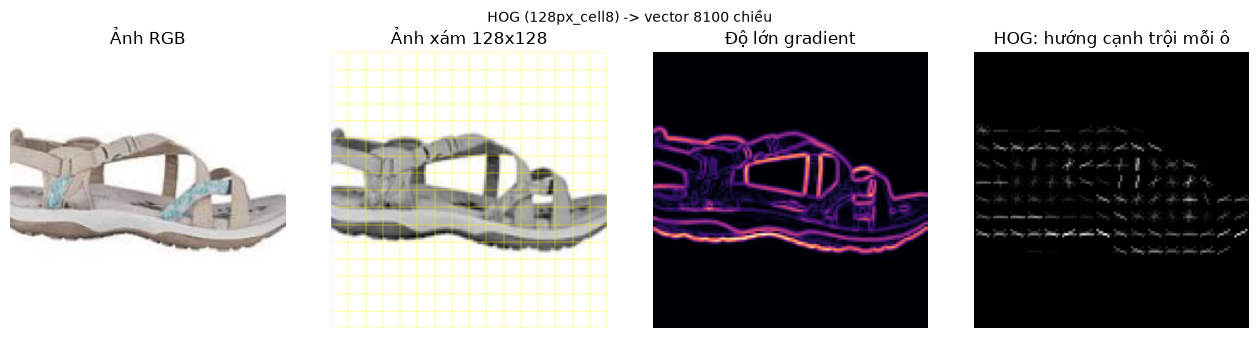

In [4]:
ex.show_hog_demo(cfg, shape_path);

**Trích HOG cho toàn bộ ảnh.** `check_features` kiểm tra số dòng khớp `meta.csv` và không có NaN/inf, rồi in: `dims` (số chiều), `zero_rows` (số ảnh có vector toàn 0, phải bằng 0), `min`/`max`, `MB` (dung lượng). Giá trị nằm trong [0, 1] do chuẩn hóa khối.

In [5]:
X, st = ex.extract_simple("hog", meta, cfg)
print(ex.check_features(X, meta), st)
ex.save_features("hog", X, cfg, st)

{'dims': 8100, 'zero_rows': 0, 'min': 0.0, 'max': 1.0, 'MB': 514.1} {'seconds': 9.4}


### 3.4. SIFT + Bag of Visual Words

Phương pháp gồm 2 tầng: **SIFT** mô tả từng vùng nhỏ của ảnh, rồi **Bag of Visual Words (BoVW)** gom hàng trăm mô tả đó thành một vector cố định cho cả ảnh.

**Tầng 1: descriptor SIFT.** Tại một điểm, lấy vùng lân cận quanh nó, chia thành **4×4 ô con**, mỗi ô con lập **histogram 8 hướng gradient** → $4 \times 4 \times 8 = 128$ chiều. Có thể xem nó như một "HOG thu nhỏ" cho một mảnh ảnh. Với tham số cỡ điểm = 16 đang đặt, OpenCV dùng ô con cạnh $3 \times 16/2 = 24$ px, nên **mỗi descriptor nhìn một vùng ≈ 96×96 px** (có trọng số Gauss giảm dần ra xa tâm), tức gần nửa ảnh 224×224. Vì các điểm chỉ cách nhau 8px nên vùng của các điểm cạnh nhau chồng lên nhau rất nhiều.
- **Chọn điểm nào? Đang dùng *dense*:** đặt điểm đều trên lưới bước 8px → $27 \times 27 = 729$ điểm/ảnh, ảnh nào cũng có đủ descriptor (kể cả ảnh trơn, ít góc cạnh). Phương án khác (`[SIFT_POINTS]` cách 2) là để SIFT tự phát hiện *keypoint* (góc, đốm nổi bật), khi đó số điểm thay đổi theo ảnh và ảnh trơn có thể gần như không có điểm nào.
- **RootSIFT:** chuẩn hóa mỗi descriptor cho tổng = 1 rồi lấy căn bậc hai từng phần tử. Việc này làm giảm ảnh hưởng của vài hướng quá trội; so sánh bằng khoảng cách Euclid sau đó tương đương so sánh histogram bằng Hellinger, thường cho kết quả tốt hơn SIFT thường.

**Tầng 2: Bag of Visual Words.** Mỗi ảnh có 729 descriptor, nhưng mô hình cần **1 vector độ dài cố định**. Ta mượn ý tưởng "túi từ" trong xử lý văn bản:
1. **Xây từ điển:** lấy ngẫu nhiên 50 descriptor từ mỗi ảnh của tập **train** (~510 000 descriptor), chạy **KMeans với k = 500 cụm**. Mỗi tâm cụm là một **"từ thị giác"**, tức một kiểu mảnh ảnh điển hình (một góc nhọn, một vạch ngang, một vùng có sọc...).
2. **Mã hóa ảnh:** gán từng descriptor của ảnh vào từ gần nhất, rồi đếm xem mỗi từ xuất hiện bao nhiêu lần → **histogram 500 chiều**, chuẩn hóa tổng = 1.

Như "túi từ", BoVW **bỏ qua vị trí**: chỉ biết ảnh chứa những loại mảnh nào và nhiều hay ít, không biết chúng nằm ở đâu. Điều này khiến nó ít nhạy khi vật bị dịch chuyển hơn HOG.

**Chống rò rỉ dữ liệu.** Từ điển chỉ được học từ tập **train**; val và final test không tham gia, nên với từ điển, ảnh val/test hoàn toàn là ảnh mới, đúng như khi mô hình gặp ảnh thật. `[BOVW_FIT]` cách 2 fit trên train + val, dùng khi đã chốt mô hình và muốn huấn luyện lại trên toàn bộ development.

**Trích SIFT + BoVW cho toàn bộ ảnh.** Đây là bước chậm nhất (~5 phút) vì phải tính SIFT hai lần: một lần lấy mẫu để fit KMeans, một lần để mã hóa mọi ảnh. Thống kê in thêm: `descriptors_mean` (số descriptor trung bình mỗi ảnh, 729 với dense), `images_without_descriptors` (số ảnh không có descriptor nào, sẽ thành vector 0), `vocab_size` (k).

In [6]:
import time
t = time.time()
results = ex.extract_sift_bovw(meta, splits, cfg)
seconds = round(time.time() - t, 1)
for name, (X, st) in results.items():
    print(name, ex.check_features(X, meta), st)
    ex.save_features(name, X, cfg, {**st, "seconds": seconds})

sift_bovw {'dims': 500, 'zero_rows': 0, 'min': 0.0, 'max': 0.6488339900970459, 'MB': 31.7} {'descriptors_mean': 729.0, 'images_without_descriptors': 0, 'vocab_size': 500}


**Minh họa SIFT + BoVW trên một ảnh.** Hình dưới: (trái) các điểm dense, một điểm ở giữa ảnh (chấm đỏ) và vùng 4×4 ô con mà descriptor của nó nhìn vào (lưới đỏ); (giữa) descriptor 128 chiều của điểm đó, mỗi màu là một ô con với 8 hướng; (phải) histogram BoVW của cả ảnh (lấy từ file đã lưu). Histogram thưa: ảnh chỉ dùng một số ít từ trong 500 từ.

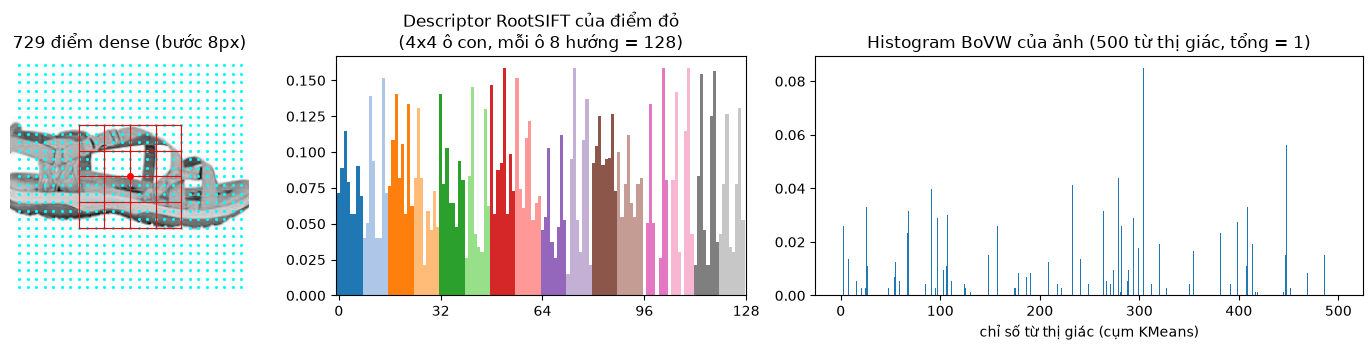

In [7]:
ex.show_sift_demo(cfg, shape_path, shape_idx, ex.load_features("sift_bovw", cfg));

### 3.5. Histogram màu HSV (`color_hist`)

**Vì sao HSV mà không phải RGB?** HSV tách **H (Hue, sắc màu)**: xanh lá, nâu, đỏ...; **S (Saturation, độ đậm)**; **V (Value, độ sáng)**. Khi ánh sáng thay đổi, chủ yếu V thay đổi còn H ít đổi, nên dễ so sánh màu hơn RGB (ở RGB cả 3 kênh cùng đổi). Trong OpenCV, H chạy 0–179, S và V chạy 0–255.

**Các bước:**
1. Đổi ảnh sang HSV.
2. Chia không gian màu thành **8 khoảng H × 4 khoảng S × 4 khoảng V = 128 "ô màu"** (histogram 3D). H được chia mịn hơn vì sắc màu là thông tin quan trọng nhất.
3. Đếm số pixel rơi vào mỗi ô màu và chia cho tổng số pixel → **tỷ lệ diện tích ảnh có màu đó** (tổng = 1, không phụ thuộc cỡ ảnh).

Histogram màu **không quan tâm vị trí**: chỉ biết ảnh có bao nhiêu phần trăm màu xanh lá, không biết màu đó nằm ở đâu.

Hình dưới: mỗi cột được tô bằng màu đại diện của ô màu đó. Chai xanh lá có các cột xanh, chai nâu có các cột cam/nâu, nhưng **cột cao nhất ở cả 3 ảnh là màu nền** (nền trắng, nền xanh xám nhạt, nền đỏ nâu). Ly thủy tinh trắng trong suốt nên histogram của nó gần như chỉ phản ánh màu nền đỏ nâu phía sau. Đây là ví dụ rõ cho thấy đặc trưng màu có thể học nhầm theo nền.

> **Lưu ý về nền ảnh** (xem lưới ảnh mẫu ở EDA mục 1.6): nhiều ảnh có nền trắng/sáng, và đặc trưng màu tính trên cả ảnh sẽ bắt luôn màu nền. Khối `[COLOR_REGION]` cách 2 chỉ tính màu trên 60% ở giữa ảnh để bớt ảnh hưởng này.

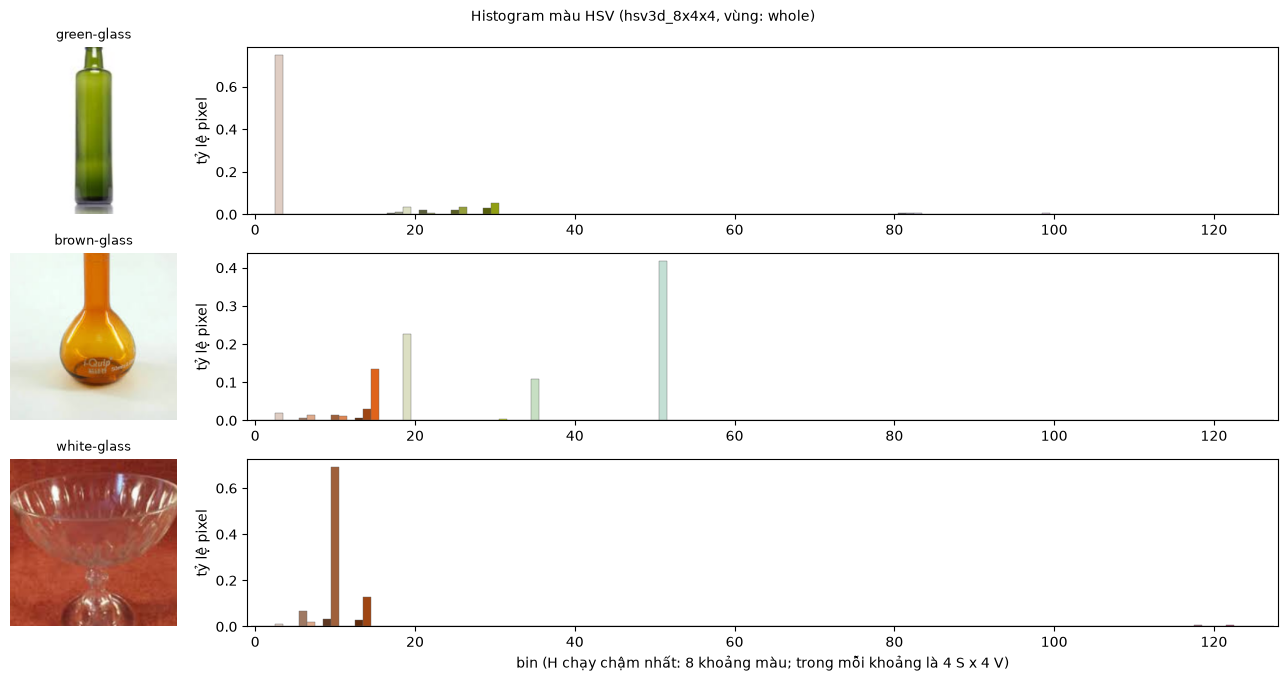

In [8]:
ex.show_color_hist_demo(cfg, examples[:3]);

**Trích histogram màu cho toàn bộ ảnh.**

In [9]:
X, st = ex.extract_simple("color_hist", meta, cfg)
print(ex.check_features(X, meta), st)
ex.save_features("color_hist", X, cfg, st)

{'dims': 128, 'zero_rows': 0, 'min': 0.0, 'max': 1.0, 'MB': 8.1} {'seconds': 5.2}


### 3.6. Color moments trong không gian Lab (`color_moments`)

**Ý tưởng.** Thay vì đếm cả phân bố màu (128 số), chỉ tóm tắt mỗi kênh màu bằng **3 con số thống kê**:
- **mean** (trung bình): màu chủ đạo;
- **std** (độ lệch chuẩn): màu đồng đều hay loang lổ;
- **skewness** (độ xiên, lấy căn bậc ba của moment bậc 3 để cùng đơn vị với màu): phân bố lệch về phía sáng hay tối.

3 kênh × 3 thống kê = **9 chiều**. Rất gọn, nhưng thô hơn histogram.

**Vì sao Lab?** **L** là độ sáng, **a** đi từ xanh lá (thấp) đến đỏ (cao), **b** đi từ xanh dương (thấp) đến vàng (cao); trong OpenCV mỗi kênh có thang 0–255 và màu trung tính (xám) có a = b ≈ 128. Lab không gặp vấn đề Hue *quay vòng* của HSV: đỏ có H ≈ 0 và H ≈ 179, nếu lấy trung bình hai giá trị này sẽ ra ≈ 90 (màu lục lam), là sai hoàn toàn. Với Lab, phép lấy trung bình có ý nghĩa.

⚠️ Thang đo của đặc trưng này (khoảng −104 đến 254) khác hẳn các đặc trưng khác (khoảng 0–1), nên **cần chuẩn hóa (vd `StandardScaler`) trước khi đưa vào Logistic Regression/SVM**.

**Trích color moments cho toàn bộ ảnh.**

In [10]:
X, st = ex.extract_simple("color_moments", meta, cfg)
print(ex.check_features(X, meta), st)
ex.save_features("color_moments", X, cfg, st)

{'dims': 9, 'zero_rows': 0, 'min': -104.48146057128906, 'max': 253.71205139160156, 'MB': 0.6} {'seconds': 15.8}


**Color moments trung bình theo lớp.** Bảng dưới là trung bình 9 giá trị theo từng lớp (tính từ file đã lưu). Ví dụ: `green-glass` có `mean_a` thấp hẳn (ngả xanh lá); `biological` và `cardboard` có `mean_b` cao (ngả vàng/nâu); `trash`/`white-glass` có `mean_L` cao và `std_L` thấp (ảnh sáng, ít tương phản).

In [11]:
ex.color_moments_by_class(ex.load_features("color_moments", cfg), meta)

,mean_L,mean_a,mean_b,std_L,std_a,std_b,skew_L,skew_a,skew_b
lớp,,,,,,,,,
battery,172.8,128.7,129.4,73.9,4.8,7.9,-39.7,2.4,4.8
biological,147.9,136.4,151.6,53.9,13.1,16.4,-20.2,6.6,3.7
brown-glass,164.4,134.5,138.9,69.3,8.1,13.4,-37.5,6.9,11.1
cardboard,167.7,133.7,145.3,41.3,4.0,9.1,-16.1,0.3,-3.5
clothes,126.9,134.9,131.8,50.0,8.4,9.8,8.7,2.8,3.9
green-glass,177.1,113.7,144.0,53.0,15.2,15.8,-31.6,-8.5,9.1
metal,167.4,129.6,131.4,53.4,4.4,6.3,-29.8,2.5,3.1
paper,169.0,130.4,133.4,48.7,6.1,7.6,-29.5,5.8,4.6
plastic,183.7,128.4,127.7,37.1,5.7,8.4,-25.5,1.6,0.7


### 3.7. LBP – Local Binary Pattern (`lbp`)

**Ý tưởng.** Mô tả **kết cấu bề mặt** (vải dệt, giấy nhăn, carton gợn sóng, kim loại bóng...) bằng cách xem mỗi pixel sáng hơn hay tối hơn các pixel xung quanh.

**Các bước** (cấu hình đang dùng `p8r1_grid4x4`):
1. Với mỗi pixel, lấy **P = 8 điểm lân cận** trên vòng tròn **bán kính R = 1**. Điểm lân cận nào **≥ pixel giữa thì ghi 1, nhỏ hơn thì ghi 0** → một chuỗi 8 bit (256 khả năng).
   ```
   ví dụ:  90  80  60          1  1  0
           95 [70] 50   ──>    1  .  0    ──> chuỗi bit quanh vòng: 1 1 0 0 0 1 1 1
           85  75  40          1  1  0
                               (đi từ góc trên trái, theo chiều kim đồng hồ)
   ```
   Chuỗi này chỉ có 2 lần đổi 0↔1 nên là mẫu *uniform* (xem bước 2), với 5 bit 1 → mã = 5. Mẫu này là một cạnh: bên trái sáng, bên phải tối.
2. **"uniform"**: chỉ giữ riêng các mẫu có **tối đa 2 lần đổi 0↔1** khi đi quanh vòng. Đó là các mẫu có ý nghĩa: điểm sáng, điểm tối, đầu mút, cạnh, góc. Mã của mẫu uniform = **số bit 1** (0..8), và mã này không đổi khi xoay mẫu. Mọi mẫu "lộn xộn" còn lại gộp chung vào 1 mã. Tổng cộng **P + 2 = 10 mã** thay vì 256.
3. Chia ảnh thành **lưới 4×4 ô**, mỗi ô lập histogram 10 mã (tổng = 1) → $16 \times 10 = 160$ chiều. Chia ô để giữ lại một chút thông tin vị trí (kết cấu ở giữa ảnh, nơi thường là vật, khác kết cấu ở góc, nơi thường là nền).

**Ưu:** không đổi khi độ sáng toàn ảnh thay đổi (vì chỉ so sánh lớn/nhỏ), tính nhanh, ít chiều. **Nhược:** không có màu và hình dạng tổng thể; nhạy với nhiễu ảnh.

Hình dưới: (giữa) mã LBP của từng pixel, đường trắng chia lưới 4×4; (phải) histogram của ô góc trên trái (ô 0, thường là nền) và một ô ở giữa ảnh (thường là vật). Hai ô có phân bố mã khác nhau.

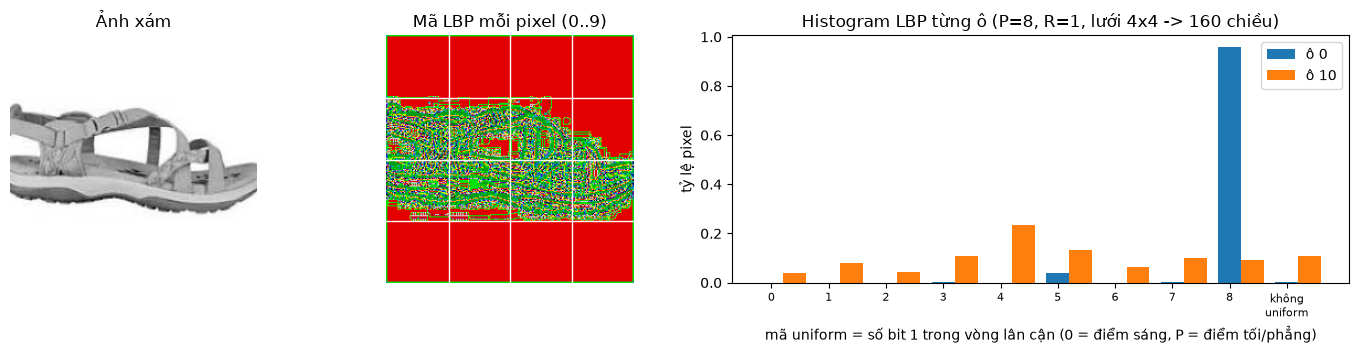

In [12]:
ex.show_lbp_demo(cfg, shape_path);

**Trích LBP cho toàn bộ ảnh.**

In [13]:
X, st = ex.extract_simple("lbp", meta, cfg)
print(ex.check_features(X, meta), st)
ex.save_features("lbp", X, cfg, st)

{'dims': 160, 'zero_rows': 0, 'min': 0.0, 'max': 1.0, 'MB': 10.2} {'seconds': 14.2}


### 3.8. Đặc trưng ghép HOG + màu (`hog_color`)

**Ý tưởng.** HOG mô tả hình dạng nhưng mù màu; histogram màu mô tả màu nhưng không biết hình dạng. Ghép hai vector lại thì mô hình thấy được cả hai.

**Vấn đề khi nối thẳng.** Hai phần có độ lớn rất chênh lệch (bảng dưới): mỗi vector HOG có độ dài (chuẩn L2) ≈ 14.6, còn vector màu chỉ ≈ 0.5. Với các mô hình dựa trên khoảng cách/tích vô hướng (SVM, Logistic Regression), phần màu khi đó gần như vô hình: tính theo bình phương độ dài, nó chỉ chiếm khoảng 0.1% ($0.5^2$ so với $14.6^2$).

**Cách đang dùng** (`[COMBINE]` cách 1): **chuẩn hóa L2 từng phần** (chia mỗi vector cho độ dài của nó, nên mọi phần đều có độ dài 1) **rồi mới nối** → 8100 + 128 = **8228 chiều**, hai phần có tầm ảnh hưởng ngang nhau. Riêng với Random Forest thì thang đo không quan trọng, nhưng phần màu vẫn ít được chọn hơn vì chỉ chiếm 128/8228 số chiều.

In [14]:
ex.norm_table({"hog": ex.load_features("hog", cfg), "color_hist": ex.load_features("color_hist", cfg)})

,số chiều,chuẩn L2 trung bình
hog,8100.0,14.630
color_hist,128.0,0.481


In [15]:
X_hog, X_col = ex.load_features("hog", cfg), ex.load_features("color_hist", cfg)
X = ex.combine_features([X_hog, X_col])
print(ex.check_features(X, meta))
ex.save_features("hog_color", X, cfg, {"parts": ["hog", "color_hist"]})

{'dims': 8228, 'zero_rows': 0, 'min': 0.0, 'max': 1.0, 'MB': 522.2}


### 3.9. Tổng hợp
Các đặc trưng đã lưu và cấu hình đã dùng (chi tiết trong file `.json` cạnh mỗi `.npy`). Cột `giây` là thời gian trích trên toàn bộ 15 866 ảnh.

In [16]:
display(ex.feature_summary(cfg))
for fn in ["hog", "sift_bovw", "color_hist", "lbp", "hog_color"]:
    info = json.load(open(os.path.join(cfg["features_dir"], fn + ".json")))
    print(fn, info["extract"])

,số dòng,số chiều,MB,dòng toàn 0,giây,ảnh không có descriptor,resize
đặc trưng,,,,,,,
color_hist,15866,128,8.1,0,5.2,NaN,short256_center_crop
color_moments,15866,9,0.6,0,15.8,NaN,short256_center_crop
hog,15866,8100,514.1,0,9.4,NaN,short256_center_crop
hog_color,15866,8228,522.2,0,NaN,NaN,short256_center_crop
lbp,15866,160,10.2,0,14.2,NaN,short256_center_crop
sift_bovw,15866,500,31.7,0,304.4,0.0,short256_center_crop


hog {'hog': '128px_cell8', 'color_region': 'whole', 'color_hist': 'hsv3d_8x4x4', 'lbp': 'p8r1_grid4x4', 'sift_points': 'dense_step8', 'resize': 'short256_center_crop'}
sift_bovw {'hog': '128px_cell8', 'color_region': 'whole', 'color_hist': 'hsv3d_8x4x4', 'lbp': 'p8r1_grid4x4', 'sift_points': 'dense_step8', 'resize': 'short256_center_crop', 'bovw_fit': 'train'}
color_hist {'hog': '128px_cell8', 'color_region': 'whole', 'color_hist': 'hsv3d_8x4x4', 'lbp': 'p8r1_grid4x4', 'sift_points': 'dense_step8', 'resize': 'short256_center_crop', 'bovw_fit': 'train'}
lbp {'hog': '128px_cell8', 'color_region': 'whole', 'color_hist': 'hsv3d_8x4x4', 'lbp': 'p8r1_grid4x4', 'sift_points': 'dense_step8', 'resize': 'short256_center_crop', 'bovw_fit': 'train'}
hog_color {'hog': '128px_cell8', 'color_region': 'whole', 'color_hist': 'hsv3d_8x4x4', 'lbp': 'p8r1_grid4x4', 'sift_points': 'dense_step8', 'resize': 'short256_center_crop', 'bovw_fit': 'train', 'combine': 'l2_each_then_concat'}


### 3.10. Tóm tắt và lưu ý cho bước phân loại (notebook 05)

| Đặc trưng | Thông tin nắm bắt | Không nắm bắt | Chiều | Lưu ý khi dùng |
|---|---|---|---|---|
| `hog` | hình dạng, đường viền theo vị trí | màu; nhạy dịch/xoay/tỷ lệ | 8100 | nhiều chiều → SVM/RF chậm; có thể thử PCA hoặc `[HOG]` ô 16 (1764 chiều) |
| `sift_bovw` | các kiểu mảnh cục bộ, ít phụ thuộc vị trí | màu; bố cục không gian | 500 | histogram tổng = 1; hợp với SVM kernel χ²/RBF |
| `color_hist` | phân bố màu (gồm cả nền) | hình dạng, vị trí | 128 | chủ yếu giúp 3 lớp thủy tinh; nên so với `[COLOR_REGION]` cách 2 |
| `color_moments` | màu chủ đạo, độ đồng đều | chi tiết phân bố màu | 9 | **phải chuẩn hóa thang đo** trước LR/SVM |
| `lbp` | kết cấu bề mặt | màu, hình dạng tổng thể | 160 | nhẹ, nhanh |
| `hog_color` | hình dạng + màu | | 8228 | đã L2-chuẩn hóa từng phần trước khi nối |

- Mọi file `.npy` có **15 866 dòng theo đúng thứ tự dòng của `data/processed/meta.csv`**; lấy từng tập bằng `meta, splits = ex.load_meta()` rồi `X[splits["train"]]`, `X[splits["val"]]`, `X[splits["test"]]`; nhãn là `meta["label"]` (mã số theo `label2id.json` của 02).
- Không có ảnh nào cho vector toàn 0, không có NaN/inf.
- Đổi một phương án trong `modules/extract.py` thì chỉ cần chạy lại phần của đặc trưng bị ảnh hưởng; file `.json` mới sẽ ghi lại phương án đã dùng để đối chiếu kết quả.